# Data Science Lifecycle — Assignment 1
## Automobile Dataset: Identifying Key Drivers of Car Price

**Student:** Musinguzi FAISAL    
**Reg_no:** S26M19/050  
**Access_no:** B40824  
**Course:** Data Science Lifecycle  
**Semester:** Advent 2026

**Objective:** Apply exploratory data analysis and statistical techniques to identify the main variables that influence car price.



## 1. LOAD DATA AND CLEAN IT 

The first cell installs any missing package automatically. The second imports the libraries and loads `automobileEDA.csv` 


In [16]:
import importlib, subprocess, sys
for pkg, mod in [("seaborn","seaborn"),("scipy","scipy"),("statsmodels","statsmodels"),
                 ("scikit-learn","sklearn"),("jinja2","jinja2")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
print("All packages available")

All packages available


In [17]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, cross_val_score, KFold

LAST_NAME = "Musinguzi"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#3987e5", "#0d366b"])
usd = FuncFormatter(lambda v, _: f"${v:,.0f}")
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", None); pd.set_option("display.width", 170)

raw = pd.read_csv("automobileEDA.csv")
continuous = ["wheel-base","length","width","height","curb-weight","engine-size","bore","stroke",
              "compression-ratio","horsepower","peak-rpm","city-mpg","highway-mpg","city-L/100km","normalized-losses"]
print("Shape:", raw.shape)
print("\nMissing per column:\n", raw.isnull().sum()[raw.isnull().sum() > 0].to_string())
print("\nExact duplicate rows:", raw.duplicated().sum())

Shape: (201, 29)

Missing per column:
 stroke               4
horsepower-binned    1

Exact duplicate rows: 0


**Interpretation:**
- The dataset has **201 rows × 29 columns**; `price` is the target and has no missing values.
- Only two columns contain missing values: `stroke` (4) and `horsepower-binned` (1).
- There are no exact duplicate rows (checked in Q1).
- `length` and `width` are scaled to 0–1, `city-L/100km` is a conversion of `city-mpg`, `horsepower-binned` is a grouping of `horsepower`, and `diesel` / `gas` are two indicator columns for one fuel-type variable. These derived columns are left out of feature selection in Q5 so the same information is not counted twice.

##  Data Cleaning 



In [18]:
# --- Missing values: who are they?
display(raw[raw.isna().any(axis=1)][["make","body-style","engine-type","bore","stroke","horsepower","horsepower-binned","price"]])

# --- Hidden mean-imputed values already in the file
print("normalized-losses equal to 122 (column mean):", int((raw["normalized-losses"]==122).sum()),
      f"({(raw['normalized-losses']==122).mean():.0%} of rows)")

# --- Duplicates
feats = [c for c in raw.columns if c != "price"]
print("\nExact duplicates:", int(raw.duplicated().sum()))
print("Rows identical in every column except price:", int(raw.duplicated(subset=feats, keep=False).sum()))

# --- Impossible values: compare suspicious bore/stroke rows with same make and engine size
print("\nSaab, engine-size 121:");     display(raw[(raw.make=="saab")&(raw["engine-size"]==121)][["body-style","bore","stroke","horsepower"]])
print("Peugot, engine-size 120:");     display(raw[(raw.make=="peugot")&(raw["engine-size"]==120)][["body-style","bore","stroke","horsepower"]])

,make,body-style,engine-type,bore,stroke,horsepower,horsepower-binned,price
46,jaguar,sedan,ohcv,3.540000,2.76,262.0,NaN,36000.0
52,mazda,hatchback,rotor,3.329751,NaN,101.0,Low,10945.0
53,mazda,hatchback,rotor,3.329751,NaN,101.0,Low,11845.0
54,mazda,hatchback,rotor,3.329751,NaN,101.0,Low,13645.0
55,mazda,hatchback,rotor,3.329751,NaN,135.0,Medium,15645.0


normalized-losses equal to 122 (column mean): 41 (20% of rows)

Exact duplicates: 0
Rows identical in every column except price: 14

Saab, engine-size 121:


,body-style,bore,stroke,horsepower
128,hatchback,3.54,3.07,110.0
129,sedan,3.54,3.07,110.0
130,hatchback,2.54,2.07,110.0
131,sedan,3.54,3.07,110.0
132,hatchback,3.54,3.07,160.0
133,sedan,3.54,3.07,160.0


Peugot, engine-size 120:


,body-style,bore,stroke,horsepower
104,sedan,3.46,3.19,97.0
106,wagon,3.46,3.19,97.0
108,sedan,3.46,2.19,95.0
110,wagon,3.46,2.19,95.0
112,sedan,3.46,3.19,97.0


**Interpretation:**
- The 4 missing `stroke` values all belong to **Mazda rotary engines** (`engine-type = rotor`), which have no piston stroke, so the gaps are structural. The 1 missing `horsepower-binned` is the 262 hp Jaguar, the most powerful car in the data, so it belongs in "High".
- The file was already partly imputed: **41 cars (20%) have `normalized-losses` = 122**, the column mean. These are not real measurements, so `normalized-losses` is treated with caution.
- **No exact duplicates.** 14 rows (7 pairs) match in every column except price (e.g. two Alfa Romeo convertibles at $13,495 and $16,500). Different prices mean different sales or trims, so they are kept.
- **Typing errors:** one Saab shows bore 2.54 / stroke 2.07 while its five twins show 3.54 / 3.07, and two Peugeots show stroke 2.19 against 3.19 for their twins. Each is off by exactly 1.00, which is a dropped leading digit.

,variable,lower_fence,upper_fence,n_outliers,pct
0,compression-ratio,7.40,10.60,27,13.4
1,stroke,2.66,3.86,20,10.0
2,price,-5312.50,29587.50,14,7.0
3,width,0.84,0.98,11,5.5
4,engine-size,33.50,205.50,10,5.0
5,normalized-losses,47.00,191.00,8,4.0
6,horsepower,1.00,185.00,5,2.5
7,wheel-base,82.65,114.25,3,1.5
8,highway-mpg,11.50,47.50,3,1.5
9,peak-rpm,3750.00,6550.00,2,1.0


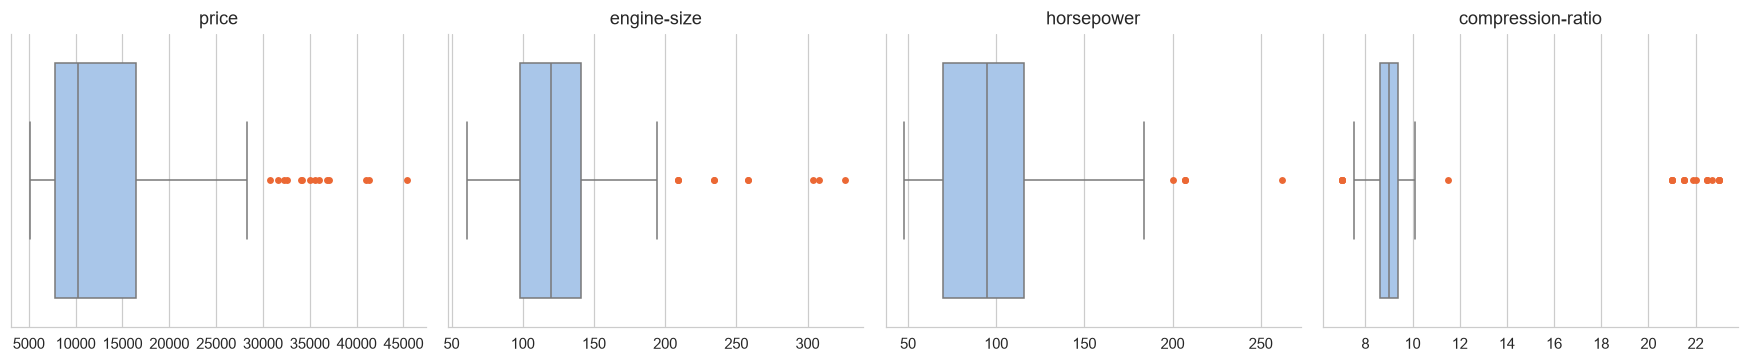

Price outliers (> $29,588) by make:
make
mercedes-benz    5
bmw              3
jaguar           3
porsche          3

Compression-ratio outliers by diesel flag:
diesel     0   1
outlier         
False    174   0
True       7  20


In [19]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return q1 - 1.5*i, q3 + 1.5*i

rows = []
for c in continuous + ["price"]:
    lo, hi = iqr_bounds(raw[c]); n = int(((raw[c] < lo) | (raw[c] > hi)).sum())
    rows.append({"variable": c, "lower_fence": round(lo,2), "upper_fence": round(hi,2), "n_outliers": n, "pct": round(100*n/len(raw),1)})
display(pd.DataFrame(rows).sort_values("n_outliers", ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, c in zip(axes, ["price","engine-size","horsepower","compression-ratio"]):
    sns.boxplot(x=raw[c], ax=ax, color="#9ec5f4", fliersize=3.5, flierprops=dict(markerfacecolor=ORANGE, markeredgecolor=ORANGE))
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout(); plt.show()

lo, hi = iqr_bounds(raw["price"])
print(f"Price outliers (> ${hi:,.0f}) by make:"); print(raw.loc[raw.price > hi, "make"].value_counts().to_string())
print("\nCompression-ratio outliers by diesel flag:")
lo_c, hi_c = iqr_bounds(raw["compression-ratio"])
print(pd.crosstab((raw["compression-ratio"]>hi_c)|(raw["compression-ratio"]<lo_c), raw["diesel"], rownames=["outlier"], colnames=["diesel"]))

**Interpretation:**
- Most flagged variables: `compression-ratio` (27 cars, 13.4%), `stroke` (20), `price` (14, 7.0%), `width` (11) and `engine-size` (10).
- All **14 price outliers are premium cars** (5 Mercedes-Benz, 3 BMW, 3 Porsche, 3 Jaguar; $30,760–$45,400) with large engines. They are genuine, and they are exactly the cars a dealer needs to price.
- The 27 `compression-ratio` outliers are also genuine: all 20 **diesel** cars (about 21–23, normal for diesels) plus 7 high-compression petrol cars.
- **Decision: keep genuine outliers.** Capping them (winsorizing) would hide the top of the market and understate the average price by about $450 (it would lower the maximum price from $45,400 to $29,588 and cut the average rwd price from $19,758 to $18,567). Only the proven typing errors are corrected.

In [20]:
clean = raw.copy()

# 1. Typing errors (dropped leading digit)
saab_bad = (clean.make=="saab") & (clean["engine-size"]==121) & (clean.bore==2.54)
clean.loc[saab_bad, ["bore","stroke"]] = [3.54, 3.07]
peu_bad = (clean.make=="peugot") & (clean["engine-size"]==120) & (clean.stroke==2.19)
clean.loc[peu_bad, "stroke"] = 3.19
print("Typing errors corrected:", int(saab_bad.sum() + peu_bad.sum()))

# 2. Missing stroke (rotary engines) -> median;  missing horsepower bin (262 hp Jaguar) -> High
clean["stroke"] = clean["stroke"].fillna(clean["stroke"].median())
clean["horsepower-binned"] = clean["horsepower-binned"].fillna("High")

# 3. Misspelt brand names
clean["make"] = clean["make"].replace({"peugot": "peugeot", "alfa-romero": "alfa-romeo"})

# 4. Duplicates: none exact; outliers kept
clean = clean.drop_duplicates().reset_index(drop=True)

print("Missing values before:", int(raw.isna().sum().sum()), "| after:", int(clean.isna().sum().sum()))
print("Shape before:", raw.shape, "| after:", clean.shape)
clean.to_csv(f"{LAST_NAME}_Data.csv", index=False)
print(f"Saved {LAST_NAME}_Data.csv")

df = clean.copy()
df["fuel-type"] = np.where(df["diesel"]==1, "diesel", "gas")     # helper column, not saved
cat_cols = ["make","fuel-type","aspiration","num-of-doors","body-style","drive-wheels","engine-location",
            "engine-type","num-of-cylinders","fuel-system","horsepower-binned","symboling"]

Typing errors corrected: 3
Missing values before: 5 | after: 0
Shape before: (201, 29) | after: (201, 29)
Saved Musinguzi_Data.csv


**Interpretation:**
- **Missing values:** 5 → 0. `stroke` was filled with the median (3.29); this is harmless because `stroke` is almost unrelated to price (r = 0.11). The Jaguar's bin was set to "High".
- **Typing errors:** 3 rows corrected; misspelt makes `peugot` and `alfa-romero` standardised.
- **Duplicates:** none to remove (the 7 pairs differing only in price are kept).
- **Outliers:** genuine values kept (see above).
- The cleaned dataset (201 × 29) is saved as `Musinguzi_Data.csv`.

## Q2. Descriptive Statistics & Distributions 

Summary statistics for continuous variables and frequency counts for categorical variables, followed by distribution plots.

In [21]:
d = df[["price"] + continuous].describe().T
d["median"] = df[["price"] + continuous].median(); d["skew"] = df[["price"] + continuous].skew()
print("=== Continuous summary ===")
display(d[["count","mean","std","min","25%","median","75%","max","skew"]].round(2))

print("\n=== Categorical frequency counts ===")
for c in ["body-style","drive-wheels","fuel-type","num-of-doors","aspiration","engine-location","num-of-cylinders","horsepower-binned"]:
    vc = df[c].value_counts()
    print(f"\n-- {c} --"); print(pd.DataFrame({"count": vc, "percent": (100*vc/len(df)).round(1)}).to_string())

=== Continuous summary ===


,count,mean,std,min,25%,median,75%,max,skew
price,201.0,13207.13,7947.07,5118.00,7775.00,10295.00,16500.00,45400.00,1.81
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90,1.03
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00,0.15
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00,0.88
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80,0.03
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00,0.71
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00,1.98
bore,201.0,3.34,0.26,2.68,3.15,3.33,3.58,3.94,0.05
stroke,201.0,3.27,0.29,2.36,3.15,3.29,3.41,4.17,-0.23
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00,2.58



=== Categorical frequency counts ===

-- body-style --
             count  percent
body-style                 
sedan           94     46.8
hatchback       68     33.8
wagon           25     12.4
hardtop          8      4.0
convertible      6      3.0

-- drive-wheels --
              count  percent
drive-wheels                
fwd             118     58.7
rwd              75     37.3
4wd               8      4.0

-- fuel-type --
           count  percent
fuel-type                
gas          181     90.0
diesel        20     10.0

-- num-of-doors --
              count  percent
num-of-doors                
four            115     57.2
two              86     42.8

-- aspiration --
            count  percent
aspiration                
std           165     82.1
turbo          36     17.9

-- engine-location --
                 count  percent
engine-location                
front              198     98.5
rear                 3      1.5

-- num-of-cylinders --
                  count  

**Interpretation:**
- `price` ranges from **$5,118 to $45,400**, mean **$13,207**, median **$10,295**, std $7,947. The mean sits above the median: a **right-skewed** distribution (skewness 1.81) in which a few luxury cars pull the mean up.
- Most skewed predictors: `compression-ratio` (2.58, a diesel cluster), `engine-size` (1.98), `horsepower` (1.15) and `wheel-base` (1.03).
- The typical car is small and light: median engine size 120, 95 hp, 2,414 curb weight, 24 city mpg.
- **Categoricals:** 90% of cars are petrol; `fwd` is 58.7%, `rwd` 37.3%, `4wd` only 4%; sedans (46.8%) and hatchbacks (33.8%) make up four in five cars; 78% are four-cylinder. Hardtop (8), convertible (6) and 4wd (8) have few cars, so their averages are less reliable.

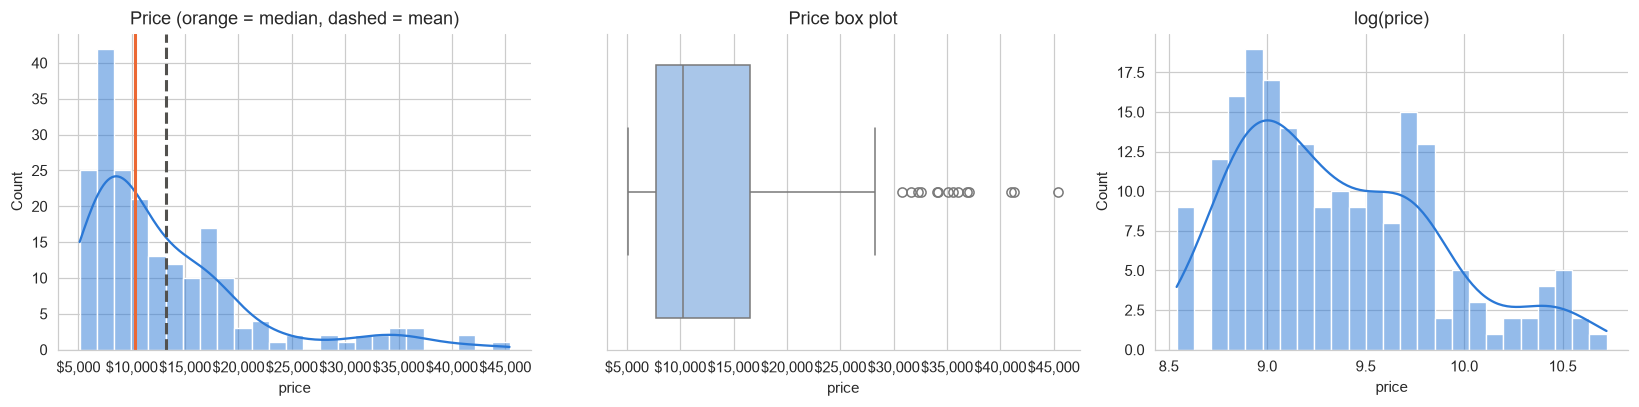

Skewness of price: 1.81 | of log(price): 0.68


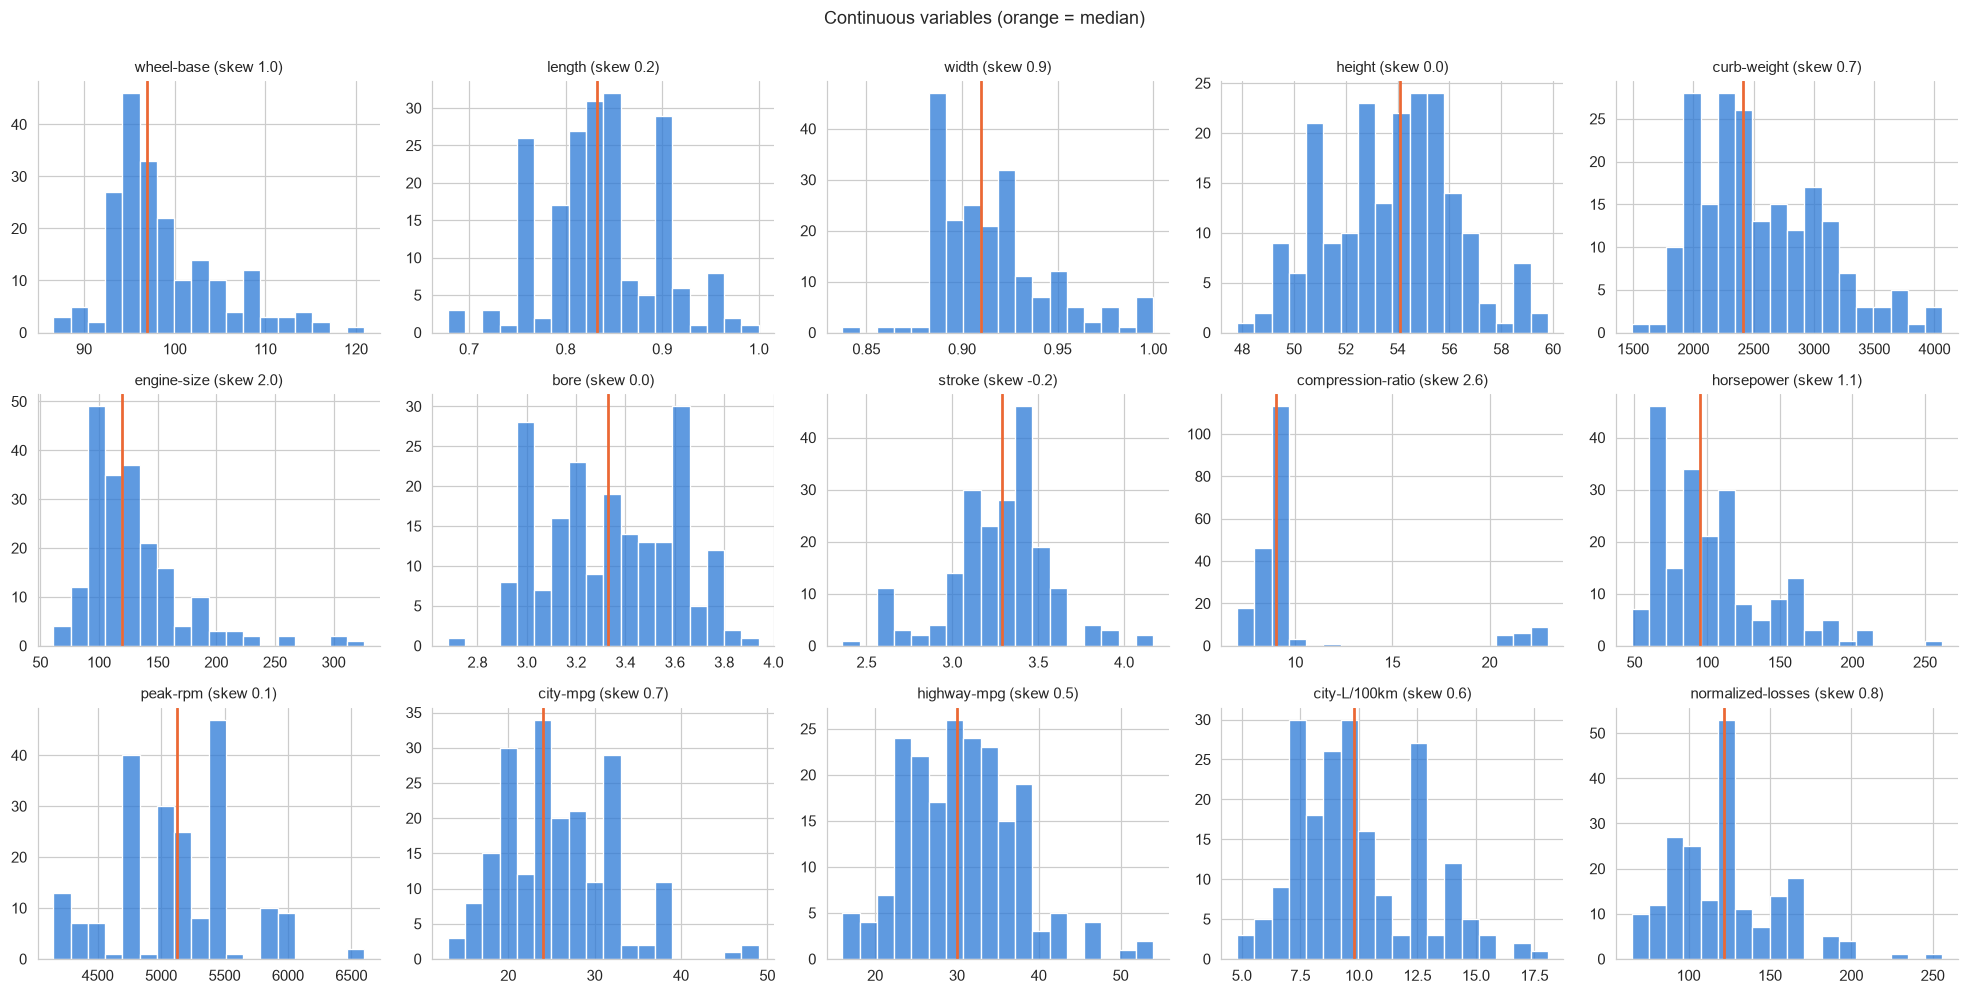

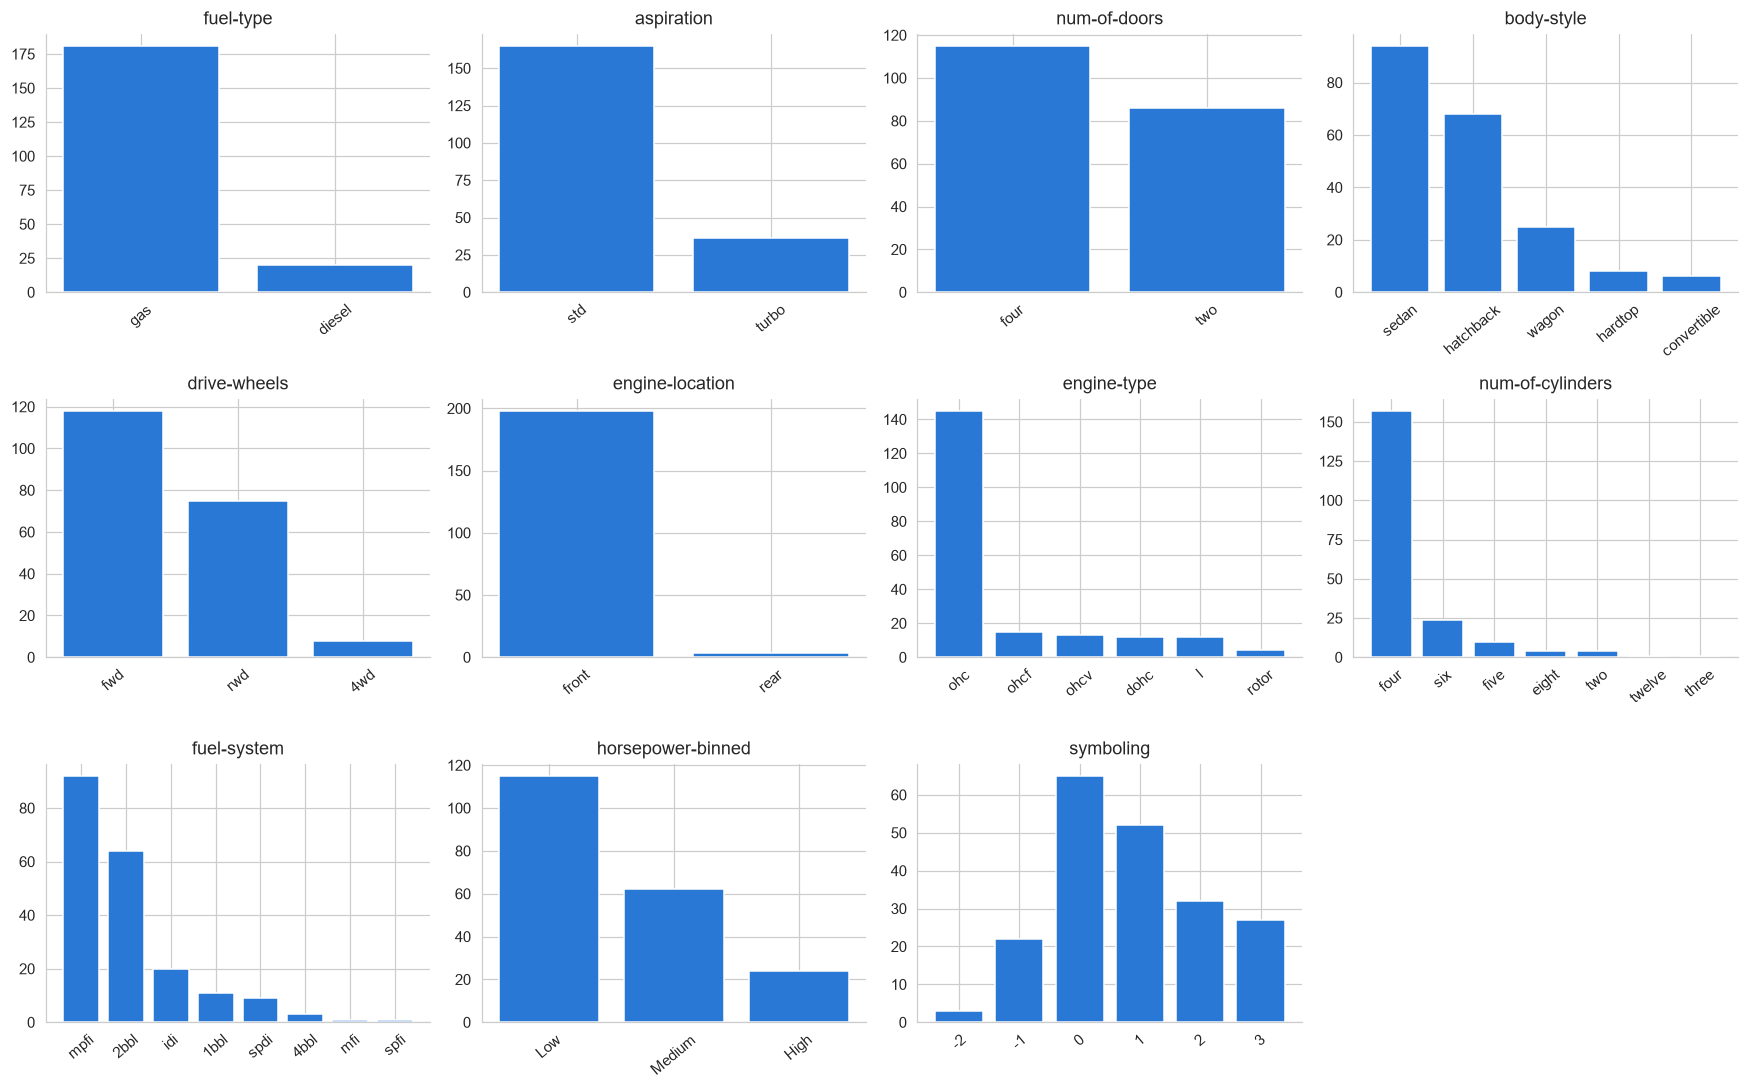

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(df["price"], bins=25, kde=True, color=BLUE, edgecolor="white", ax=axes[0])
axes[0].axvline(df.price.median(), color=ORANGE, lw=2); axes[0].axvline(df.price.mean(), color="#52514e", lw=2, ls="--")
axes[0].set_title("Price (orange = median, dashed = mean)"); axes[0].xaxis.set_major_formatter(usd)
sns.boxplot(x=df["price"], color="#9ec5f4", ax=axes[1]); axes[1].set_title("Price box plot"); axes[1].xaxis.set_major_formatter(usd)
sns.histplot(np.log(df["price"]), bins=25, kde=True, color=BLUE, edgecolor="white", ax=axes[2]); axes[2].set_title("log(price)")
plt.tight_layout(); plt.show()
print(f"Skewness of price: {df.price.skew():.2f} | of log(price): {np.log(df.price).skew():.2f}")

fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, c in zip(axes.flatten(), continuous):
    sns.histplot(df[c], bins=18, color=BLUE, edgecolor="white", ax=ax); ax.axvline(df[c].median(), color=ORANGE, lw=1.8)
    ax.set_title(f"{c} (skew {df[c].skew():.1f})", fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Continuous variables (orange = median)", y=1.0); plt.tight_layout(); plt.show()

small = [c for c in cat_cols if c != "make"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.flatten(), small):
    vc = df[c].value_counts() if c != "symboling" else df[c].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color=BLUE); ax.set_title(c); ax.tick_params(axis="x", rotation=40)
for ax in axes.flatten()[len(small):]: ax.set_visible(False)
plt.tight_layout(); plt.show()

**Interpretation:**
- `price` has a long right tail (most cars under $16,500, a few above $40,000). Taking the log reduces skewness from **1.81 to 0.68**, so log-price is much more symmetric.
- `engine-size`, `horsepower` and `wheel-base` are right-skewed, and **`compression-ratio` is bimodal**: petrol cars near 8–10, diesel cars near 21–23.
- `highway-mpg` and `city-mpg` are **right-skewed** (skewness +0.55 and +0.68): most cars sit at 20–35 mpg, with a tail of very efficient small cars up to 49–54 mpg.
- `normalized-losses` has a spike at 122 (the filler value found in Q1).
- The bar charts show the sample is dominated by petrol, standard-aspiration, front-engine, four-cylinder, front-wheel-drive sedans and hatchbacks.

## Q3. Group Analysis: Average Price by Drive-Wheels and Body-Style 

Mean, median, count and standard error of price for each group, followed by ANOVA, a two-way table and a heatmap.

=== Price by drive-wheels ===


,n,mean_price,median_price,std,sem
drive-wheels,,,,,
rwd,75,19758.0,16900.0,9083.0,1049.0
4wd,8,10241.0,9006.0,3288.0,1163.0
fwd,118,9245.0,8192.0,3346.0,308.0


=== Price by body-style ===


,n,mean_price,median_price,std,sem
body-style,,,,,
hardtop,8,22208.0,19688.0,14556.0,5146.0
convertible,6,21890.0,17084.0,11188.0,4567.0
sedan,94,14460.0,11078.0,8523.0,879.0
wagon,25,12372.0,11694.0,5121.0,1024.0
hatchback,68,9957.0,8672.0,4149.0,503.0


=== Price by drive-wheels x body-style ===


n  mean_price  median_price      std     sem
drive-wheels body-style                                                
rwd          hardtop       7     24203.0       28176.0  14493.0  5478.0
             convertible   5     23950.0       17669.0  11165.0  4993.0
             sedan        36     21712.0       18382.0   9195.0  1532.0
             wagon         9     16994.0       16515.0   4687.0  1562.0
             hatchback    18     14338.0       14645.0   3832.0   903.0
4wd          sedan         3     12647.0       11259.0   4281.0  2472.0
fwd          convertible   1     11595.0       11595.0      NaN     NaN
             wagon        12      9997.0        8921.0   3584.0  1035.0
             sedan        55      9812.0        8558.0   3520.0   475.0
4wd          wagon         4      9096.0        8396.0   1776.0   888.0
fwd          hatchback    49      8396.0        7689.0   3005.0   429.0
             hardtop       1      8249.0        8249.0      NaN     NaN
4wd          hatchback     1      7603.0        7603.0      NaN     NaN

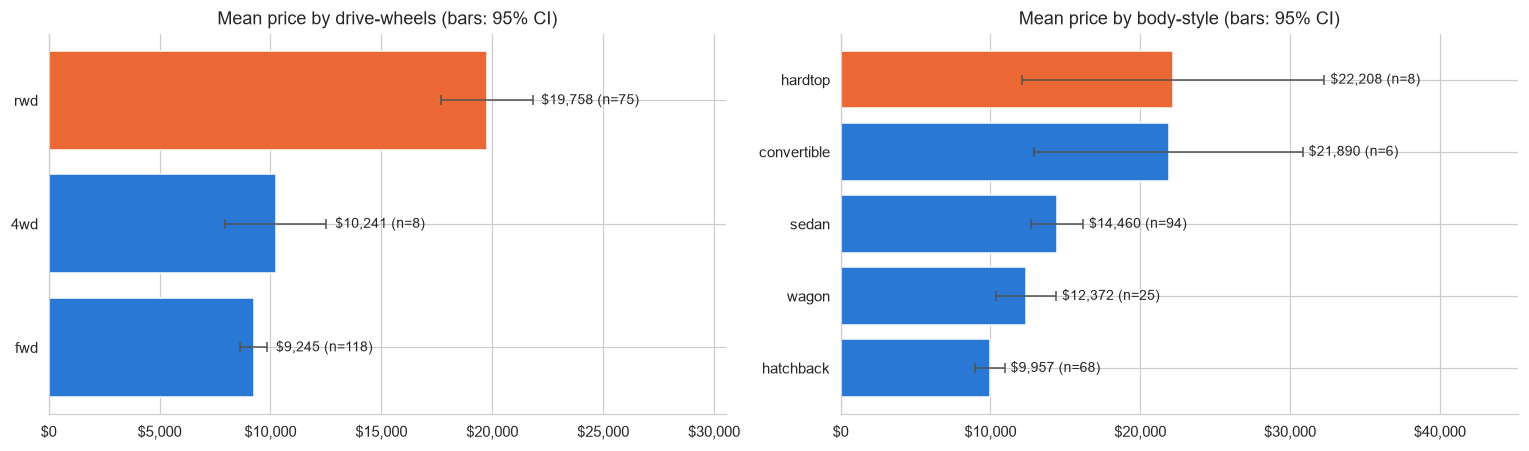

In [23]:
def gstats(by):
    return df.groupby(by)["price"].agg(n="count", mean_price="mean", median_price="median", std="std", sem="sem").sort_values("mean_price", ascending=False)
g_dw, g_bs, g_both = gstats("drive-wheels"), gstats("body-style"), gstats(["drive-wheels","body-style"])
print("=== Price by drive-wheels ==="); display(g_dw.round(0))
print("=== Price by body-style ===");   display(g_bs.round(0))
print("=== Price by drive-wheels x body-style ==="); display(g_both.round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, tbl, name in zip(axes, [g_dw, g_bs], ["drive-wheels","body-style"]):
    t = tbl.sort_values("mean_price"); err = 1.96*t["sem"].fillna(0)
    ax.barh(t.index, t["mean_price"], xerr=err, color=[ORANGE if v==t.mean_price.max() else BLUE for v in t.mean_price],
            error_kw=dict(ecolor="#52514e", lw=1, capsize=3))
    for y,(m,e,n) in enumerate(zip(t.mean_price, err, t.n)): ax.text(m+e+400, y, f"${m:,.0f} (n={n})", va="center", fontsize=9)
    ax.set_title(f"Mean price by {name} (bars: 95% CI)"); ax.xaxis.set_major_formatter(usd); ax.set_xlim(0, (t.mean_price+err).max()*1.4)
plt.tight_layout(); plt.show()

**Interpretation:**
- **By drive-wheels:** rwd **$19,758** (n = 75), 4wd $10,241 (n = 8), fwd **$9,245** (n = 118). Rear-wheel drive costs about twice as much as front-wheel drive.
- **By body-style:** hardtop **$22,208** (n = 8), convertible $21,890 (n = 6), sedan $14,460 (n = 94), wagon $12,372 (n = 25), hatchback **$9,957** (n = 68).
- The 95% intervals show the rwd–fwd gap and the hatchback–sedan gap are clearly real. Hardtop and convertible have very wide intervals (only 8 and 6 cars), so we can say both are expensive but not which is dearer.
- Medians are below means in every group, again because of the skew.

ANOVA drive-wheels: F=68.0, p=3.39e-23
ANOVA body-style:   F=9.1, p=8.78e-07


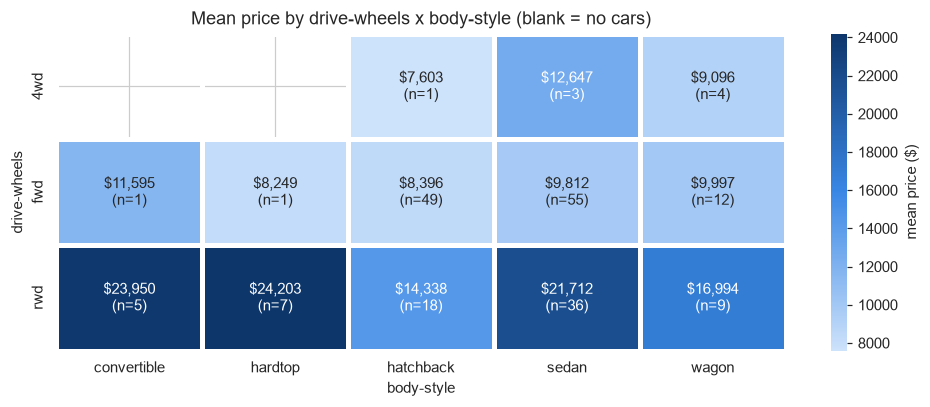

drive-wheels  highest: rwd ($19,758)   lowest: fwd ($9,245)
body-style    highest: hardtop ($22,208)   lowest: hatchback ($9,957)
combined (groups with n>=5) highest: ('rwd', 'hardtop') $24,203 | lowest: ('fwd', 'hatchback') $8,396


In [24]:
f_d, p_d = stats.f_oneway(*[g.price.values for _, g in df.groupby("drive-wheels")])
f_b, p_b = stats.f_oneway(*[g.price.values for _, g in df.groupby("body-style")])
print(f"ANOVA drive-wheels: F={f_d:.1f}, p={p_d:.2e}"); print(f"ANOVA body-style:   F={f_b:.1f}, p={p_b:.2e}")

piv = df.pivot_table(index="drive-wheels", columns="body-style", values="price", aggfunc="mean")
cnt = pd.crosstab(df["drive-wheels"], df["body-style"]).reindex(index=piv.index, columns=piv.columns)
lab = piv.copy().astype(object)
for i in piv.index:
    for j in piv.columns: lab.loc[i,j] = "" if pd.isna(piv.loc[i,j]) else f"${piv.loc[i,j]:,.0f}\n(n={cnt.loc[i,j]})"
plt.figure(figsize=(9, 3.8))
sns.heatmap(piv, annot=lab.values, fmt="", cmap=SEQ, linewidths=2, linecolor="white", cbar_kws={"label": "mean price ($)"})
plt.title("Mean price by drive-wheels x body-style (blank = no cars)"); plt.tight_layout(); plt.show()

for name, tbl in [("drive-wheels", g_dw), ("body-style", g_bs)]:
    hi, lo = tbl.mean_price.idxmax(), tbl.mean_price.idxmin()
    print(f"{name:13s} highest: {hi} (${tbl.loc[hi,'mean_price']:,.0f})   lowest: {lo} (${tbl.loc[lo,'mean_price']:,.0f})")
big = g_both[g_both.n >= 5]
print("combined (groups with n>=5) highest:", big.mean_price.idxmax(), f"${big.mean_price.max():,.0f}",
      "| lowest:", big.mean_price.idxmin(), f"${big.mean_price.min():,.0f}")

**Interpretation:**
- Both ANOVA tests are **highly significant** (drive-wheels F = 68.0, p ≈ 3e-23; body-style F = 9.1, p ≈ 9e-7): mean price differs between the groups.
- **Highest / lowest:** drive-wheels → **rwd** highest, **fwd** lowest; body-style → **hardtop** highest, **hatchback** lowest.
- **Combined groups (at least 5 cars):** **rwd hardtop** is highest ($24,203, n = 7) and **fwd hatchback** is lowest ($8,396, n = 49). (4wd hatchback is lower on paper at $7,603 but it is a single car.)
- Within every body style that has both drive types, rwd costs more: hatchback $14,338 vs $8,396, sedan $21,712 vs $9,812, wagon $16,994 vs $9,997. So the drive-wheels effect is not just a body-style effect.
- Cells with 1 car (4wd hatchback, fwd convertible, fwd hardtop) are not reliable.

## Q4. Effect of Independent Attributes on Price

### (a) Continuous variables vs. price 

,variable,pearson_r,p_value,spearman_rho,r_squared,slope_$_per_unit
0,engine-size,0.872,9.3e-64,0.828,0.761,166.9
1,curb-weight,0.834,2.2e-53,0.914,0.696,12.8
2,horsepower,0.810,6.4e-48,0.849,0.655,172.2
3,city-L/100km,0.790,3.9e-44,0.831,0.624,2476.7
4,width,0.751,9.2e-38,0.812,0.564,204554.6
5,highway-mpg,-0.705,1.7e-31,-0.827,0.497,-821.7
6,length,0.691,8.0e-30,0.810,0.477,92690.7
7,city-mpg,-0.687,2.3e-29,-0.831,0.471,-849.5
8,wheel-base,0.585,8.1e-20,0.682,0.342,765.9
9,bore,0.559,6.5e-18,0.657,0.312,16919.8


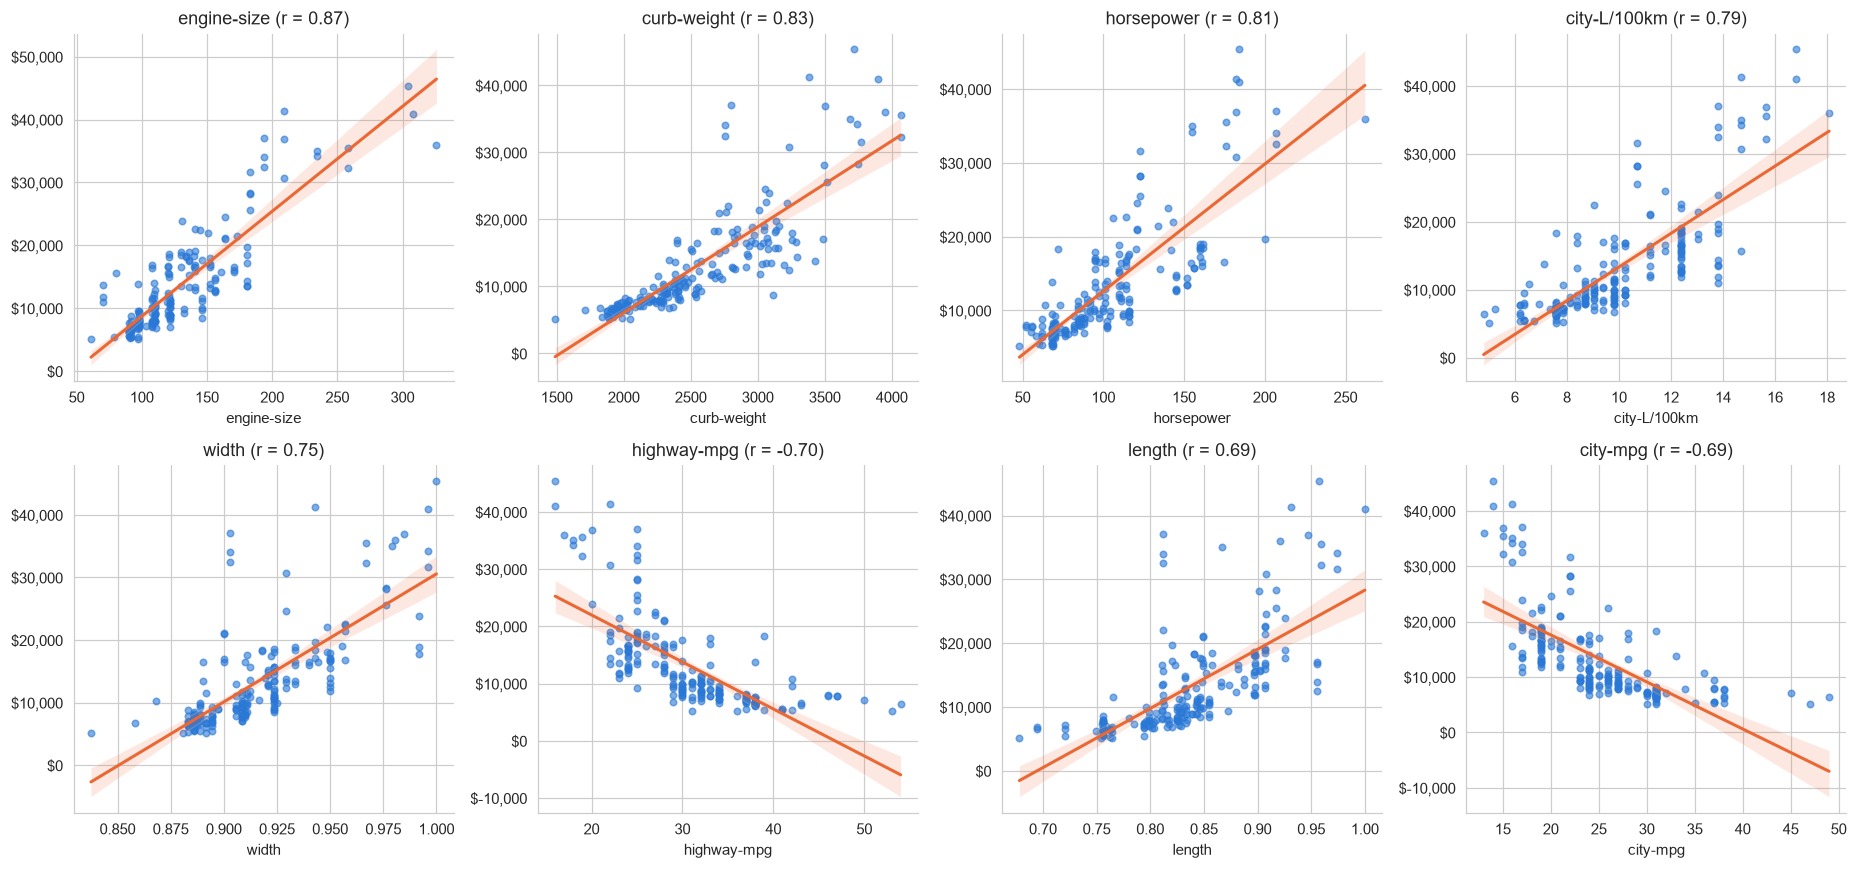

,r_all,r_without_14_outliers
engine-size,0.872,0.750
curb-weight,0.834,0.855
horsepower,0.810,0.722
city-L/100km,0.790,0.708
width,0.751,0.790
highway-mpg,-0.705,-0.686
length,0.691,0.732
city-mpg,-0.687,-0.671


In [25]:
rows = []
for c in continuous:
    r, p = stats.pearsonr(df[c], df.price); rho, _ = stats.spearmanr(df[c], df.price)
    rows.append({"variable": c, "pearson_r": round(r,3), "p_value": f"{p:.1e}", "spearman_rho": round(rho,3),
                 "r_squared": round(r*r,3), "slope_$_per_unit": round(stats.linregress(df[c], df.price).slope,1)})
corr_tbl = pd.DataFrame(rows).sort_values("pearson_r", key=abs, ascending=False).reset_index(drop=True)
display(corr_tbl)

top8 = corr_tbl.variable.head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, c in zip(axes.flatten(), top8):
    sns.regplot(data=df, x=c, y="price", ax=ax, scatter_kws=dict(s=18, alpha=0.6, color=BLUE), line_kws=dict(color=ORANGE, lw=2))
    ax.set_title(f"{c} (r = {df[c].corr(df.price):.2f})"); ax.yaxis.set_major_formatter(usd); ax.set_ylabel("")
plt.tight_layout(); plt.show()

# Sensitivity: do the 14 premium outliers drive the result?
lo_, hi_ = iqr_bounds(df.price); keep = df.price <= hi_
sens = pd.DataFrame({"r_all": [df[c].corr(df.price) for c in top8], "r_without_14_outliers": [df.loc[keep,c].corr(df.loc[keep,"price"]) for c in top8]}, index=top8)
display(sens.round(3))

**Interpretation:**
- **Strong positive:** `engine-size` (r = 0.87, R² = 0.76), `curb-weight` (0.83), `horsepower` (0.81), `city-L/100km` (0.79), `width` (0.75), `length` (0.69), `wheel-base` (0.59), `bore` (0.56).
- **Strong negative:** `highway-mpg` (−0.71) and `city-mpg` (−0.69). Efficient cars are small, so this is not a causal effect of mpg. (`city-L/100km` is the reverse scale of `city-mpg`, hence the opposite sign.)
- **No significant linear relationship** (p > 0.05): `height` (0.135), `normalized-losses` (0.134), `stroke` (0.108), `peak-rpm` (−0.102), `compression-ratio` (0.071).
- In dollars: about **$167 per unit of engine size**, $172 per horsepower, about $1,280 per 100 units of curb weight and −$822 per extra highway mpg.
- **Robustness:** removing the 14 premium outliers changes some correlations (engine-size 0.87 → 0.75, horsepower 0.81 → 0.72, curb-weight 0.83 → 0.86) but all stay above 0.67, so the conclusion holds. Note the predictors are strongly correlated with each other (engine-size with curb-weight 0.85, city-mpg with highway-mpg 0.97), so they carry overlapping information.

### (b) Categorical variables vs. price

,variable,n_levels,F,p_anova,eta_squared,p_kruskal
0,make,22,34.9,4.0e-51,0.796,8.0e-17
1,num-of-cylinders,7,76.3,8.9e-39,0.630,9.3e-16
2,horsepower-binned,3,108.5,1.5e-32,0.523,3.8e-23
3,drive-wheels,3,68.0,3.4e-23,0.407,5.8e-21
4,fuel-system,8,21.0,9.6e-17,0.353,1.7e-24
5,engine-type,6,9.8,2.1e-08,0.202,3.7e-07
6,body-style,5,9.1,8.8e-07,0.157,5.0e-05
7,symboling,6,6.8,6.6e-06,0.149,4.9e-11
8,engine-location,2,24.5,1.6e-06,0.110,5.4e-03
9,aspiration,2,6.6,1.1e-02,0.032,1.5e-05


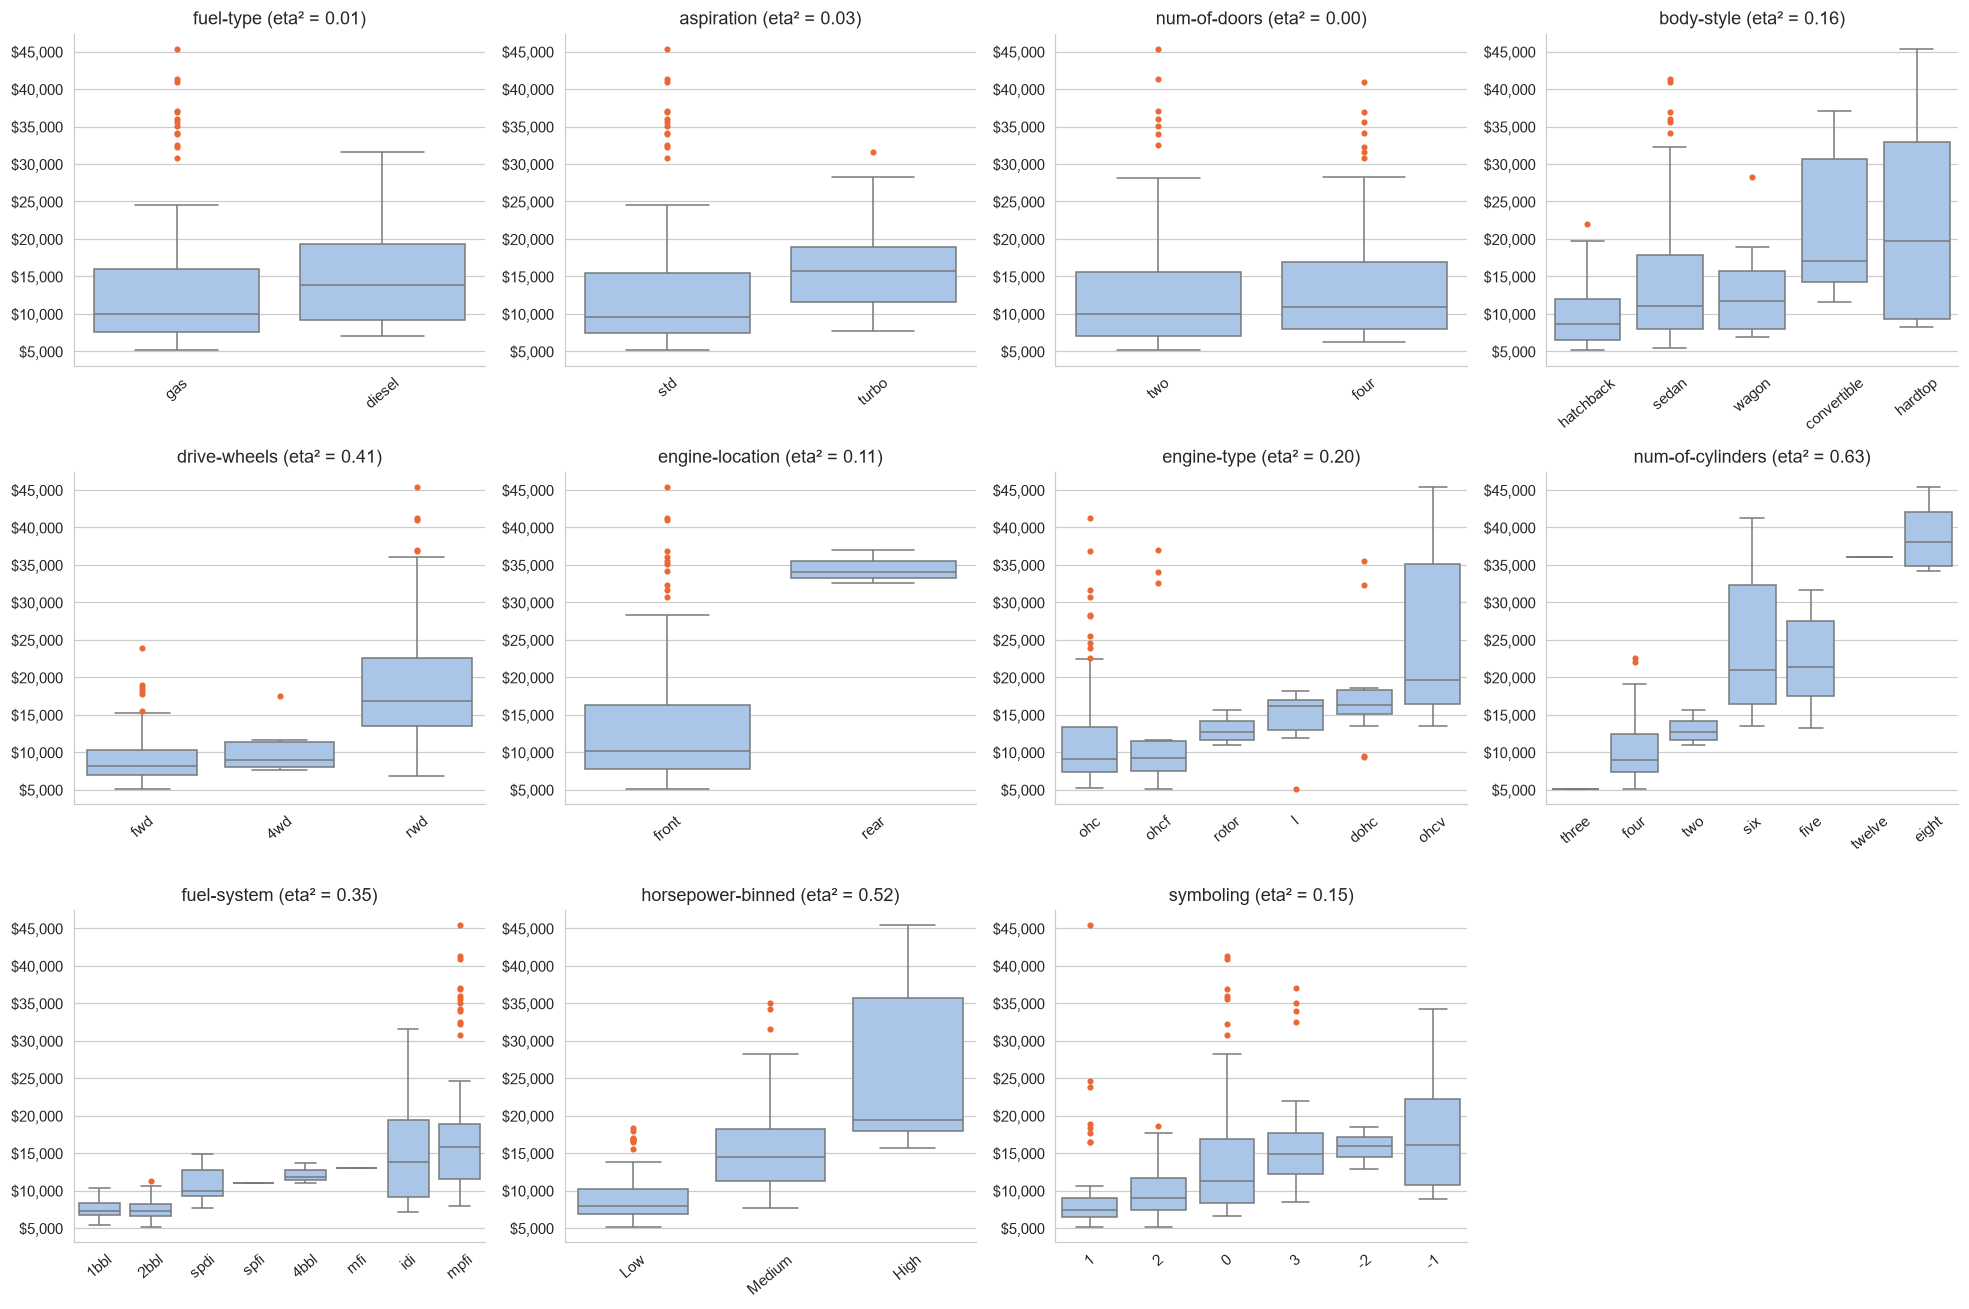


Tukey HSD, price by drive-wheels
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
group1 group2  meandiff  p-adj    lower      upper    reject
------------------------------------------------------------
   4wd    fwd  -996.2203 0.8974 -6302.5087   4310.068  False
   4wd    rwd  9516.6133 0.0001  4114.6082 14918.6184   True
   fwd    rwd 10512.8337    0.0  8367.9755 12657.6919   True
------------------------------------------------------------

Tukey HSD, price by body-style
         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
   group1     group2    meandiff  p-adj     lower      upper    reject
----------------------------------------------------------------------
convertible   hardtop       318.0    1.0 -10641.7206 11277.7206  False
convertible hatchback -11933.0588 0.0018 -20575.6081 -3290.5096   True
convertible     sedan  -7430.7447 0.1212 -15975.8326  1114.3432  False
convertible     wagon    -9518.54 0.0395 -18744.0695  -293.0105   True
    hardto

In [26]:
def eta_sq(col):
    g = df.price.mean(); ssb = sum(len(x)*(x.price.mean()-g)**2 for _, x in df.groupby(col))
    return ssb / ((df.price-g)**2).sum()
rows = []
for c in cat_cols:
    gr = [x.price.values for _, x in df.groupby(c) if len(x) > 1]
    F, p = stats.f_oneway(*gr); H, pk = stats.kruskal(*gr)
    rows.append({"variable": c, "n_levels": df[c].nunique(), "F": round(F,1), "p_anova": f"{p:.1e}", "eta_squared": round(eta_sq(c),3), "p_kruskal": f"{pk:.1e}"})
eta_tbl = pd.DataFrame(rows).sort_values("eta_squared", ascending=False).reset_index(drop=True)
display(eta_tbl)

small = [c for c in cat_cols if c != "make"]
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, c in zip(axes.flatten(), small):
    order = df.groupby(c)["price"].median().sort_values().index
    sns.boxplot(data=df, x=c, y="price", order=order, color="#9ec5f4", fliersize=3, ax=ax, flierprops=dict(markerfacecolor=ORANGE, markeredgecolor=ORANGE))
    ax.set_title(f"{c} (eta² = {eta_sq(c):.2f})"); ax.set_xlabel(""); ax.set_ylabel(""); ax.yaxis.set_major_formatter(usd); ax.tick_params(axis="x", rotation=40)
for ax in axes.flatten()[len(small):]: ax.set_visible(False)
plt.tight_layout(); plt.show()

for col in ["drive-wheels", "body-style"]:
    print(f"\nTukey HSD, price by {col}"); print(pairwise_tukeyhsd(df.price, df[col], alpha=0.05).summary())

**Interpretation:**
- Nine of twelve categorical variables are significantly related to price (ANOVA p < 0.001). By **η²** (share of price variance explained): `make` 0.80, `num-of-cylinders` 0.63, `horsepower-binned` 0.52, `drive-wheels` 0.41, `fuel-system` 0.35, `engine-type` 0.20, `body-style` 0.16, `symboling` 0.15, `engine-location` 0.11. (η² grows with the number of levels, so `make` with 22 levels is flattered.)
- **`aspiration` is significant but small** (η² = 0.03, p = 0.011); **`fuel-type` (η² = 0.01, ANOVA p = 0.12) and `num-of-doors` (η² = 0.002, p = 0.55) have essentially no effect.** Kruskal–Wallis agrees except that `fuel-type` reaches p = 0.041 and `num-of-doors` p = 0.064 — neither effect is large enough to matter. So not *every* categorical variable is significant.
- Price rises with cylinders (four $10,303, six $23,672, eight $38,900) and horsepower band (Low $9,012, Medium $15,913, High $26,320). `mpfi` fuel systems average $17,605 against about $7,500 for `1bbl`/`2bbl`.
- **Tukey tests:** rwd is about $10,513 dearer than fwd and $9,517 dearer than 4wd (both p ≤ 0.0001), while 4wd and fwd do not differ significantly (p = 0.90). Hatchbacks are significantly cheaper than sedans ($4,502, p = 0.0016), hardtops and convertibles; sedan vs wagon (p = 0.72) and hatchback vs wagon (p = 0.63) do not differ. In effect: premium tier (hardtop, convertible), middle (sedan, wagon), budget (hatchback).

### (c) Two categorical variables

Are drive-wheels and body-style associated with each other (χ² test), and do they affect price together (two-way ANOVA with interaction)?

drive-wheels x body-style: chi2=29.1, dof=8, p=3.03e-04, Cramer's V=0.27, cells with expected<5: 60%


body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,0,0,1,3,4
fwd,1,1,49,55,12
rwd,5,7,18,36,9


Cars used in two-way ANOVA: 179 of 201


,sum_sq,df,F,PR(>F)
C(drive_wheels),3.474817e+09,1.0,129.8942,0.0000
C(body_style),4.287821e+08,2.0,8.0143,0.0005
C(drive_wheels):C(body_style),3.228576e+08,2.0,6.0345,0.0029
Residual,4.627948e+09,173.0,NaN,NaN


R-squared: 0.498


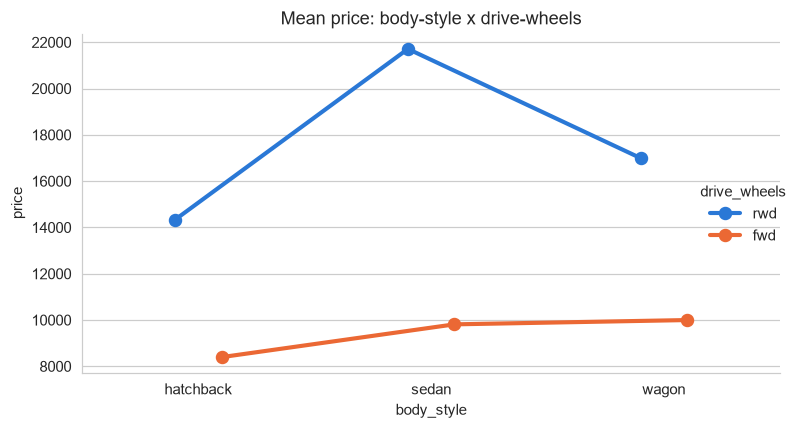

In [27]:
ct = pd.crosstab(df["drive-wheels"], df["body-style"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape)-1)))
print(f"drive-wheels x body-style: chi2={chi2:.1f}, dof={dof}, p={p:.2e}, Cramer's V={v:.2f}, cells with expected<5: {(exp<5).mean():.0%}")
display(ct)

tmp = df.rename(columns={"drive-wheels": "drive_wheels", "body-style": "body_style"})
sub = tmp[tmp.drive_wheels.isin(["fwd","rwd"]) & tmp.body_style.isin(["hatchback","sedan","wagon"])]   # fully crossed part
print("Cars used in two-way ANOVA:", len(sub), "of", len(tmp))
model = smf.ols("price ~ C(drive_wheels) * C(body_style)", data=sub).fit()
display(sm.stats.anova_lm(model, typ=2).round(4)); print(f"R-squared: {model.rsquared:.3f}")

sns.catplot(data=sub, x="body_style", y="price", hue="drive_wheels", kind="point", errorbar=None, dodge=0.2,
            order=["hatchback","sedan","wagon"], palette=[BLUE, ORANGE], height=4, aspect=1.6)
plt.title("Mean price: body-style x drive-wheels"); plt.tight_layout(); plt.show()

**Interpretation:**
- **Association:** drive-wheels and body-style are related (χ² = 29.1, p = 0.0003, Cramér's V = 0.27, modest). rwd dominates hardtops (7 of 8) and convertibles (5 of 6); fwd dominates hatchbacks (49 of 68). 60% of cells have an expected count below 5, so the p-value is approximate.
- **Joint effect on price:** the two-way ANOVA (179 cars with every drive × body combination present: fwd/rwd by hatchback/sedan/wagon) shows drive-wheels (F = 129.9, p < 0.0001), body-style (F = 8.0, p = 0.0005) and their **interaction** (F = 6.0, p = 0.0029) are all significant. The rwd premium is about $5,900 for hatchbacks, $11,900 for sedans and $7,000 for wagons, while fwd prices barely move ($8,396 to $9,997).
- Together the two variables explain about **50% of the price variance** (R² = 0.498), against 41% for drive-wheels alone. Hence a dealer should segment by **both** drivetrain and body style.

## Q5. Feature Selection & Dealer Recommendation

Three complementary signals, combined into one ranking:
1. **Association strength** — |Pearson r| for continuous variables, √η² for categorical ones.
2. **Mutual information** with price (captures non-linear relationships).
3. **Random-forest permutation importance** on a held-out test set.

Derived duplicates are excluded (`city-L/100km`, `horsepower-binned`, `diesel`, `gas`); categoricals are integer-coded, and missing values are already handled in Q1 (the original crash came from the 4 missing `stroke` values).

Random forest R2 on 51 hold-out cars: 0.929


,association,mutual_info,rf_permutation,mean_rank
curb-weight,0.834,0.899,0.300,2.000
engine-size,0.872,0.837,0.356,2.333
horsepower,0.810,0.846,0.024,3.333
highway-mpg,0.705,0.854,0.016,4.667
width,0.751,0.669,0.021,5.333
make,0.892,0.556,0.007,5.667
city-mpg,0.687,0.734,0.011,6.667
length,0.691,0.585,0.002,8.333
wheel-base,0.585,0.587,0.003,9.000
num-of-cylinders,0.794,0.333,0.002,9.333


Weakest five: engine-location, peak-rpm, compression-ratio, fuel-type, num-of-doors


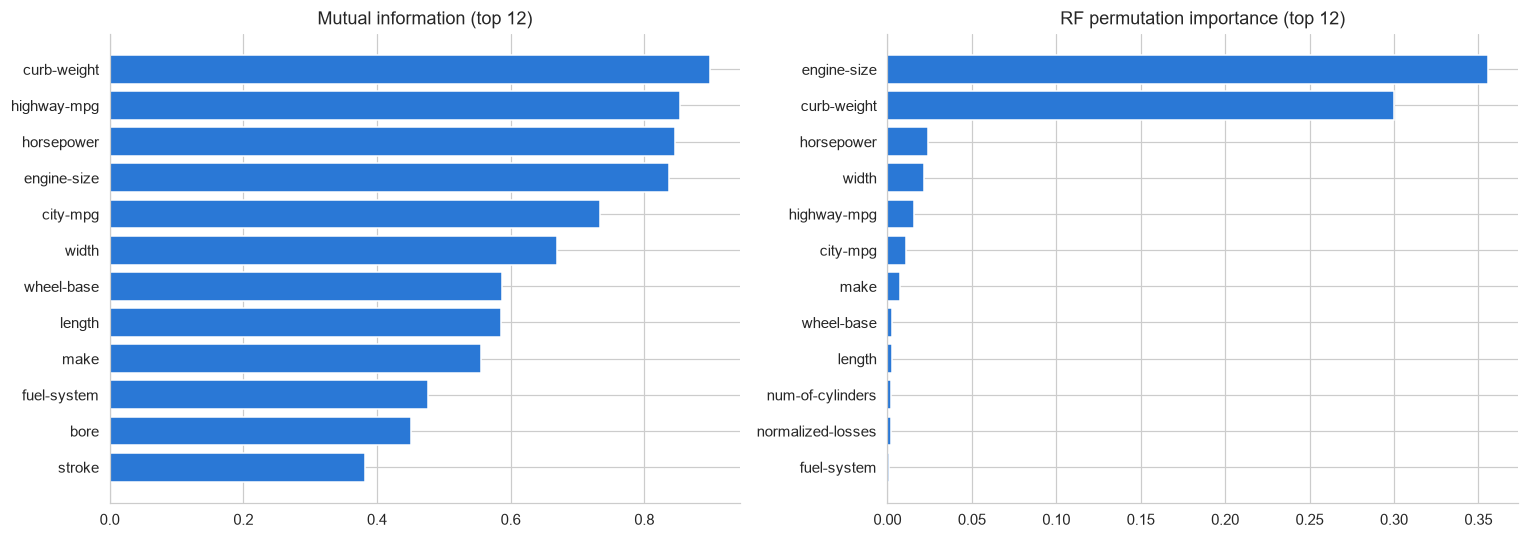

In [30]:
num_feats = [c for c in continuous if c != "city-L/100km"]
cat_feats = [c for c in cat_cols if c != "horsepower-binned"]
X = df[num_feats + cat_feats].copy()
for c in cat_feats: X[c] = pd.factorize(df[c], sort=True)[0]
y = df["price"]
assert not X.isna().any().any()

assoc = pd.concat([corr_tbl.set_index("variable")["pearson_r"].abs(), np.sqrt(eta_tbl.set_index("variable")["eta_squared"])])
mi = pd.Series(mutual_info_regression(X, y, discrete_features=np.array([c in cat_feats for c in X.columns]), random_state=42), index=X.columns)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1).fit(Xtr, ytr)
print(f"Random forest R2 on {len(yte)} hold-out cars: {rf.score(Xte, yte):.3f}")
perm = pd.Series(permutation_importance(rf, Xte, yte, n_repeats=30, random_state=42, n_jobs=-1).importances_mean, index=X.columns)

fs = pd.DataFrame({"association": assoc, "mutual_info": mi, "rf_permutation": perm}).loc[X.columns]
fs["mean_rank"] = fs.rank(ascending=False).mean(axis=1)
fs = fs.sort_values("mean_rank"); display(fs.round(3).head(12))
print("Weakest five:", ", ".join(fs.index[-5:]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
t = mi.sort_values().tail(12); axes[0].barh(t.index, t.values, color=BLUE); axes[0].set_title("Mutual information (top 12)")
t = perm.sort_values().tail(12); axes[1].barh(t.index, t.values, color=BLUE); axes[1].set_title("RF permutation importance (top 12)")
plt.tight_layout(); plt.show()

**Interpretation:**
- The forest predicts the 51 hold-out cars with **R² = 0.929**, so the features carry enough information to price cars well.
- **Combined ranking:** 1 `curb-weight`, 2 `engine-size`, 3 `horsepower`, 4 `highway-mpg`, 5 `width`, 6 `make`, 7 `city-mpg`, 8 `length`, 9 `wheel-base`, 10 `num-of-cylinders`.
- Permutation importance is dominated by `engine-size` (0.36) and `curb-weight` (0.30); the rest are small because the strong predictors are correlated (once the model has engine size and weight, shuffling horsepower costs little).
- **Weakest five:** `engine-location`, `peak-rpm`, `compression-ratio`, `fuel-type`, `num-of-doors` — consistent with Q4.
- Redundancy: `city-L/100km` is a transform of `city-mpg`, and `diesel`/`gas` are one variable, so they were left out.

In [29]:
ranked = fs.index.tolist(); cv = KFold(5, shuffle=True, random_state=42); rows = []
for k in [1, 2, 3, 5, 8, 12, len(ranked)]:
    sc = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), X[ranked[:k]], y, cv=cv, scoring="r2")
    rows.append({"top_k": k, "last_feature_added": ranked[k-1], "cv_r2": round(sc.mean(),3), "cv_std": round(sc.std(),3)})
display(pd.DataFrame(rows))

# Do drive-wheels and body-style still matter once size and weight are accounted for?
m2 = smf.ols("price ~ Q('engine-size') + Q('curb-weight') + C(Q('drive-wheels'), Treatment('fwd')) + C(Q('body-style'), Treatment('sedan'))", data=df).fit()
coef = pd.DataFrame({"coef_$": m2.params.round(1), "p_value": m2.pvalues.round(3)})
coef.index = [i.replace("C(Q('drive-wheels'), Treatment('fwd'))","drive").replace("C(Q('body-style'), Treatment('sedan'))","body").replace("Q('","").replace("')","") for i in coef.index]
display(coef); print(f"Adjusted R-squared: {m2.rsquared_adj:.3f}")

,top_k,last_feature_added,cv_r2,cv_std
0,1,curb-weight,0.580,0.161
1,2,engine-size,0.816,0.097
2,3,horsepower,0.858,0.067
3,5,width,0.883,0.052
4,8,length,0.888,0.047
5,12,bore,0.888,0.047
6,25,num-of-doors,0.884,0.051


,coef_$,p_value
Intercept,-11550.3,0.000
drive[T.4wd],399.9,0.761
drive[T.rwd],1914.3,0.010
body[T.convertible],3255.1,0.030
body[T.hardtop],1578.2,0.252
body[T.hatchback],-996.1,0.084
body[T.wagon],-2068.4,0.014
engine-size,98.2,0.000
curb-weight,4.7,0.000


Adjusted R-squared: 0.812


**Interpretation:**
- **About five features carry all the predictive power:** `curb-weight` alone gives cross-validated R² = 0.58, two features 0.82, three 0.86, five 0.883; eight, twelve and all 25 give 0.888 / 0.888 / 0.884. Adding more gives no gain.
- **After controlling for size and weight**, each extra unit of engine size adds about **$98** and each extra unit of curb weight about **$4.70** (both p < 0.001). The rwd premium over fwd shrinks from about $10,500 to about **$1,900** (p = 0.010), and 4wd is no different from fwd. Relative to sedans, convertibles are about $3,255 higher (p = 0.030) and wagons about $2,068 lower (p = 0.014). Most of the drive-wheels gap seen in Q3 therefore comes from rwd cars being bigger and heavier. (Adjusted R² = 0.81; these are associations, not proof of cause.)

## Recommendation for a Car Dealer

> Car price is driven mainly by **engine size and vehicle mass**. `curb-weight`, `engine-size`, `horsepower` and `width` carry most of the signal (r between 0.75 and 0.87), and `highway-mpg` is an inverse proxy for size (efficient cars are small).
>
> **Practical pricing guidance:**
> 1. **Start from engine size and curb weight.** On their own the slopes are about $167 per unit of engine size and $1,280 per 100 units of weight; holding the other fixed, about $98 and $470.
> 2. **Adjust for brand tier.** Average prices run from about $6,000–$8,000 (Chevrolet, Dodge, Plymouth, Honda) to $26,000–$35,000 (BMW, Porsche, Mercedes-Benz, Jaguar) for the same kind of car.
> 3. **Add smaller adjustments for body and drive:** a modest premium for rear-wheel drive (about $1,900) and convertibles (about $3,300), and a discount for wagons and hatchbacks. The raw rwd gap of about $10,500 is mostly because rwd cars are bigger.
> 4. **Do not price on number of doors or fuel type**, and treat fuel economy as a positioning message, not a separate price driver.
> 5. **Caveat:** this is a 201-car, apparently historical sample, with several brands having three or fewer cars and only 14 cars above $29,600. Recalibrate on the dealer's current sales and refit regularly.



